# 02 · Pit Stop Strategy Optimisation

Uses the degradation models from `01` to find the fastest strategy.

**Model:** race time = Σ stint tyre losses + stops × pit loss (fuel and SC laps cancel between strategies).
Brute-forces every legal 1- and 2-stop plan (two dry compounds required), then stress-tests the best ones with a Monte Carlo safety-car simulation.

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("f1strat"):
    REPO = "https://github.com/anerudh-k/f1-tyre-strategy"
    !git clone -q {REPO} repo && cp -r repo/* .
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1strat import *
COLORS = {"SOFT": "#e10600", "MEDIUM": "#f5c400", "HARD": "#8a8a8a"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)

In [2]:
MODEL_FILE = "data/deg_generic_2026_las_vegas.json"
PIT_LOSS = None
PIT_LOSS_SC = 11.0
P_SC = 0.5
WEAR_SD = 0.0

if not os.path.exists(MODEL_FILE) and "generic" in MODEL_FILE:
    raise FileNotFoundError(f"{MODEL_FILE} not found - run notebook 03 first")
if not os.path.exists(MODEL_FILE):
    print("Model file not found - fitting it now (same steps as notebook 01)...")
    _, _year, _gp = MODEL_FILE.replace(".json", "").split("_", 2)
    _, _laps = load_race(int(_year), _gp.replace("_", " ").title())
    _tl = int(_laps["LapNumber"].max())
    _m = fit_all(fuel_correct(clean_laps(_laps), _tl))
    os.makedirs("data", exist_ok=True)
    save_models(_m, MODEL_FILE, meta=dict(year=int(_year), gp=_gp.replace("_", " ").title(),
                total_laps=_tl, pit_loss_est=pit_loss_from_session(_laps)))
models, meta = load_models(MODEL_FILE)
TOTAL_LAPS = meta["total_laps"]
est = meta.get("pit_loss_est")
PIT_LOSS = PIT_LOSS or (est if est and est == est else 21.0)
if meta.get("p_sc") is not None and meta["p_sc"] == meta["p_sc"]:
    P_SC = meta["p_sc"]
WEAR_SD = meta.get("wear_sd", WEAR_SD)
setup = RaceSetup(TOTAL_LAPS, pit_loss=PIT_LOSS, pit_loss_sc=PIT_LOSS_SC, models=models)
print(meta.get("event"), meta.get("year"), "| laps:", TOTAL_LAPS, "| pit loss:", round(PIT_LOSS, 1),
      "s | P(SC):", round(P_SC, 2))
print({c: setup.max_stint(c) for c in models}, "<- max stint per compound")

Las Vegas 2026 (generic model) 2026 | laps: 50 | pit loss: 23.0 s | P(SC): 0.33
{'SOFT': 30, 'MEDIUM': 27, 'HARD': 34} <- max stint per compound


## 1. Deterministic optimum (no safety car)

In [3]:
strats = enumerate_strategies(setup)
best = best_per_sequence(strats)
print(f"{len(strats):,} legal strategies evaluated")
best[["Stops", "Compounds", "PitLaps", "Stints", "Gap"]].head(10).round(2)

12,046 legal strategies evaluated


,Stops,Compounds,PitLaps,Stints,Gap
0,1,H-S,"(23,)","(23, 27)",0.00
1,1,S-H,"(27,)","(27, 23)",0.00
2,1,M-S,"(20,)","(20, 30)",3.79
3,1,S-M,"(30,)","(30, 20)",3.79
4,1,M-H,"(20,)","(20, 30)",10.23
5,1,H-M,"(30,)","(30, 20)",10.23
6,2,S-H-S,"(18, 32)","(18, 14, 18)",12.15
7,2,H-S-S,"(14, 32)","(14, 18, 18)",12.15
8,2,S-S-H,"(18, 36)","(18, 18, 14)",12.15
9,2,M-S-S,"(10, 30)","(10, 20, 20)",12.77


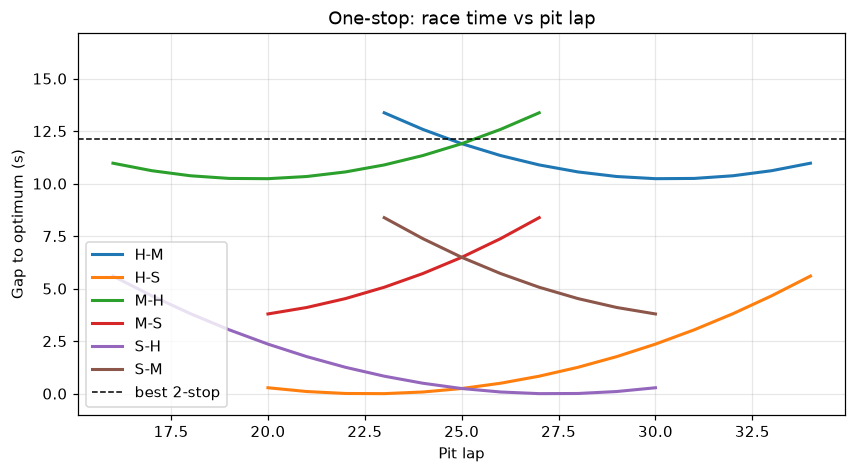

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
one = strats[strats["Stops"] == 1]
for comp, g in one.groupby("Compounds"):
    g = g.sort_values("PitLaps")
    ax.plot([p[0] for p in g["PitLaps"]], g["Gap"], lw=2, label=comp)
two_best = strats[strats["Stops"] == 2]["Gap"].min()
ax.axhline(two_best, c="k", ls="--", lw=1, label="best 2-stop")
ax.set(xlabel="Pit lap", ylabel="Gap to optimum (s)", title="One-stop: race time vs pit lap",
       ylim=(-1, max(15, two_best + 5)))
ax.legend(); plt.savefig("figures/one_stop_window.png", bbox_inches="tight")

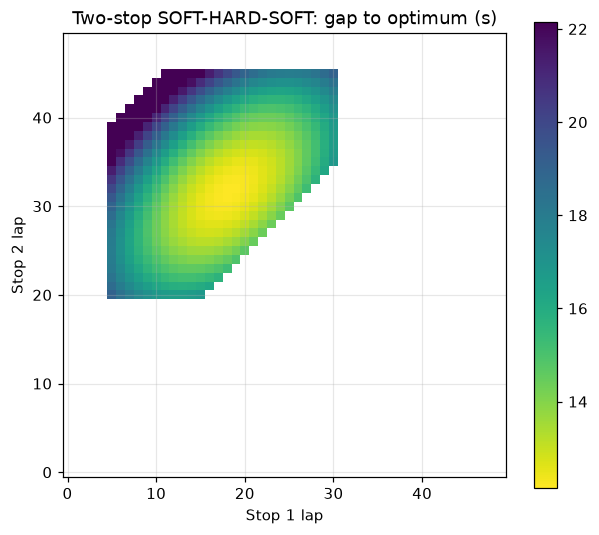

In [5]:
seq = strats[strats["Stops"] == 2].iloc[0]["Seq"]
g = strats[strats["Seq"] == seq]
grid = np.full((TOTAL_LAPS, TOTAL_LAPS), np.nan)
for p, t in zip(g["PitLaps"], g["Gap"]):
    grid[p[1], p[0]] = t
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(grid, origin="lower", cmap="viridis_r", vmax=np.nanmin(grid) + 10)
ax.set(xlabel="Stop 1 lap", ylabel="Stop 2 lap", title=f"Two-stop {'-'.join(seq)}: gap to optimum (s)")
plt.colorbar(im); plt.savefig("figures/two_stop_map.png", bbox_inches="tight")

## 2. Sensitivity: when does a two-stop win?

,pit_loss,best_1stop,best_2stop,two_minus_one
0,16.0,"S-H (27,)","S-S-H (18, 36)",5.11
1,17.0,"H-S (23,)","H-S-S (14, 32)",6.11
2,18.0,"S-H (27,)","S-H-S (18, 32)",7.11
3,19.0,"H-S (23,)","H-S-S (14, 32)",8.11
4,20.0,"H-S (23,)","S-S-H (18, 36)",9.11
5,21.0,"H-S (23,)","H-S-S (14, 32)",10.11
6,22.0,"H-S (23,)","S-S-H (18, 36)",11.11
7,23.0,"H-S (23,)","S-H-S (18, 32)",12.11
8,24.0,"H-S (23,)","H-S-S (14, 32)",13.11
9,25.0,"H-S (23,)","S-S-H (18, 36)",14.11


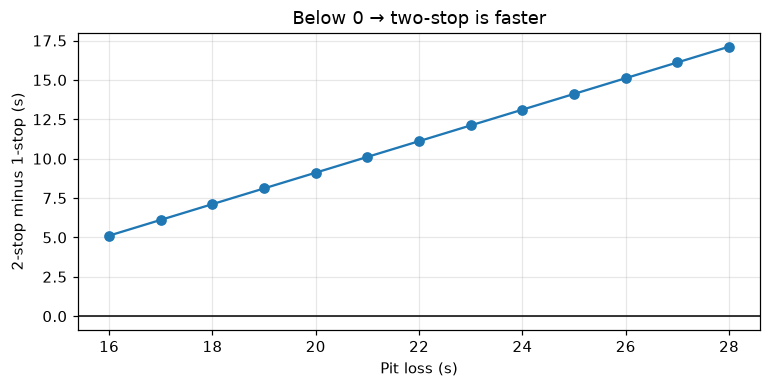

In [6]:
rows = []
for pl in np.arange(16, 28.5, 1.0):
    s = RaceSetup(TOTAL_LAPS, pit_loss=pl, models=models)
    st = enumerate_strategies(s)
    b1 = st[st.Stops == 1].iloc[0]; b2 = st[st.Stops == 2].iloc[0]
    rows.append(dict(pit_loss=pl, best_1stop=f"{b1.Compounds} {b1.PitLaps}",
                     best_2stop=f"{b2.Compounds} {b2.PitLaps}", two_minus_one=b2.RaceTime - b1.RaceTime))
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(sens.pit_loss, sens.two_minus_one, "o-"); ax.axhline(0, c="k", lw=1)
ax.set(xlabel="Pit loss (s)", ylabel="2-stop minus 1-stop (s)", title="Below 0 → two-stop is faster")
plt.savefig("figures/pit_loss_sensitivity.png", bbox_inches="tight"); sens.round(2)

## 3. Monte Carlo: robustness to safety cars
Each simulated race may get a safety car at a random lap. If a planned stop is within 6 laps, the car pits under SC instead (cheaper stop). With a generic model, tyre wear is also uncertain: each simulated race draws its own wear rates (± `WEAR_SD`). Win rate = how often each plan is the fastest.

In [7]:
cands = best.head(6)
mc, times = monte_carlo(setup, cands, n_sims=5000, p_sc=P_SC, wear_sd=WEAR_SD)
mc.sort_values("MeanTime").round(2)

,Compounds,PitLaps,NoSC_Time,MeanTime,P10,P90,WinRate
0,H-S,"(23,)",51.91,51.14,36.43,65.75,0.26
1,S-H,"(27,)",51.91,51.14,36.43,65.75,0.26
2,M-S,"(20,)",55.71,54.86,38.91,70.47,0.16
3,S-M,"(30,)",55.71,55.10,39.29,70.58,0.15
5,H-M,"(30,)",62.15,61.35,45.17,77.29,0.09
4,M-H,"(20,)",62.15,61.37,45.32,77.30,0.08


C:\Users\Anerudh K\AppData\Local\Temp\ipykernel_25404\1408468813.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0].boxplot([times[:, i] - times.min() for i in order], vert=False, whis=(5, 95), showfliers=False)


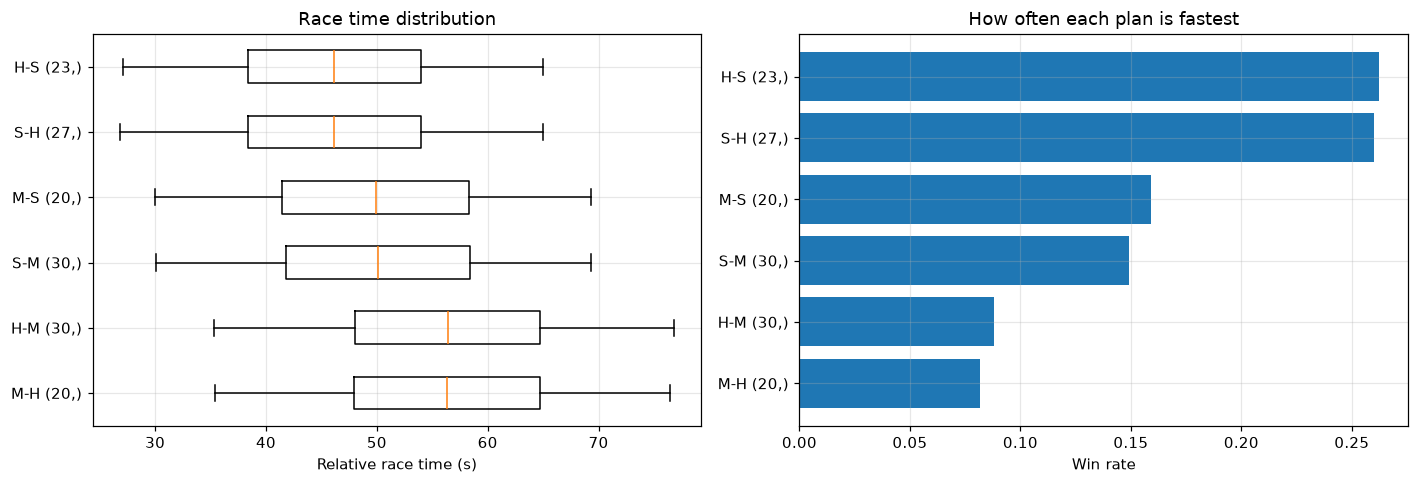

In [8]:
order = mc["MeanTime"].argsort().to_numpy()
labels = [f"{mc.Compounds[i]} {mc.PitLaps[i]}" for i in order]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].boxplot([times[:, i] - times.min() for i in order], whis=(5, 95), showfliers=False, orientation="horizontal")
ax[0].set_yticklabels(labels); ax[0].set(xlabel="Relative race time (s)", title="Race time distribution")
ax[1].barh(labels, mc["WinRate"].to_numpy()[order]); ax[1].invert_yaxis()
ax[0].invert_yaxis(); ax[1].set(xlabel="Win rate", title="How often each plan is fastest")
plt.tight_layout(); plt.savefig("figures/monte_carlo.png", bbox_inches="tight")

## 4. Compare with what teams actually did

In [9]:
try:
    _, laps_raw = load_race(meta["year"], meta["gp"]) if not MODEL_FILE.endswith("demo.json") else (None, None)
except Exception as e:
    print("No actual race data to compare with:", e); laps_raw = None
if laps_raw is not None:
    res = (laps_raw.groupby(["Driver", "Stint"]).agg(Compound=("Compound", "first"),
           Laps=("LapNumber", "count")).reset_index())
    actual = res.groupby("Driver").apply(lambda g: " → ".join(f"{c[0]}{n}" for c, n in zip(g.Compound, g.Laps)))
    if "Position" in laps_raw:
        final = laps_raw.groupby("Driver")["Position"].last().sort_values()
    else:
        g = laps_raw.groupby("Driver").agg(n=("LapNumber", "max"), t=("LapTime", "sum"))
        final = g.sort_values(["n", "t"], ascending=[False, True]).assign(r=range(1, len(g) + 1))["r"]
    display(pd.DataFrame({"Finish": final, "Strategy": actual}).head(10))

No actual race data to compare with: not run yet


## Findings
Results below are for Las Vegas 2026, using the tyre model from notebook 03 (50 laps, 23.0 s pit loss, safety car in 1 of the last 3 races).
- The fastest plan is a one-stop on Soft and Hard: Hard until lap 23 then Soft, or Soft until lap 27 then Hard. Both give the same time, because the model has no track position or tyre warm-up, so the order of the stints does not matter.
- The one-stop window is flat. The best Soft-Hard plans stay within about 1 s of the optimum over several laps either side. Soft-Medium is about 4 s slower and Medium-Hard about 10 s slower, mainly because of the high Medium wear carried over from the 2024 race, when the cold track caused heavy graining.
- A two-stop never pays at this track. It is 5 s slower even with a 16 s pit loss and 17 s slower at 28 s. With wear of 0.04 to 0.07 s/lap there is not enough time to gain back from an extra stop.
- In 5,000 simulated races with random safety cars and uncertain wear (±0.024 s/lap), the Soft-Hard one-stop is fastest in about 52% of races (26% for each order), Soft-Medium in about 31% and Medium-Hard in about 17%.
- Limitations: no undercut or overcut, no track position or traffic, at most one safety car per race, and linear wear with no cliff. The best plan has a 27-lap Soft stint, longer than any Soft stint seen at Las Vegas (24 laps), so `stint_cap_factor=1.0` is the safer setting.

**Next step:** add an undercut model (out-lap on new tyres vs in-lap on old) and a track-position penalty.